In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path
import warnings
import joblib

from sklearn.model_selection import train_test_split, cross_val_score

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.pipeline import Pipeline

from sklearn.impute import SimpleImputer

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    RocCurveDisplay
)

warnings.filterwarnings("ignore")

sns.set_theme(style="whitegrid")

print("Machine Learning libraries imported successfully!")

Machine Learning libraries imported successfully!


In [2]:
PROJECT_ROOT = Path.cwd()

if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent

DATA_PATH = (
    PROJECT_ROOT
    / "data"
    / "processed"
    / "employee_attrition_cleaned.csv"
)

df = pd.read_csv(DATA_PATH)

print("Dataset loaded successfully!")
print("Dataset Shape:", df.shape)

display(df.head())

Dataset loaded successfully!
Dataset Shape: (1470, 35)


,Age,Attrition,BusinessTravel,DailyRate,Department,DistanceFromHome,Education,EducationField,EmployeeCount,EmployeeID,...,RelationshipSatisfaction,StandardHours,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager
0,41,Yes,Travel_Rarely,1102,Sales,1,2,Life Sciences,1,1,...,1,80,0,8,0,1,6,4,0,5
1,49,No,Travel_Frequently,279,Research & Development,8,1,Life Sciences,1,2,...,4,80,1,10,3,3,10,7,1,7
2,37,Yes,Travel_Rarely,1373,Research & Development,2,2,Other,1,4,...,2,80,0,7,3,3,0,0,0,0
3,33,No,Travel_Frequently,1392,Research & Development,3,4,Life Sciences,1,5,...,3,80,0,8,3,3,8,7,3,0
4,27,No,Travel_Rarely,591,Research & Development,2,1,Medical,1,7,...,4,80,1,6,3,3,2,2,2,2


In [3]:
# Target variable
y = df["Attrition"].map({
    "No": 0,
    "Yes": 1
})

# Remove target and employee identifier from features
X = df.drop(
    columns=["Attrition", "EmployeeID"],
    errors="ignore"
)

print("Features Shape:", X.shape)
print("Target Shape:", y.shape)

print("\nTarget Distribution:")
print(y.value_counts())

Features Shape: (1470, 33)
Target Shape: (1470,)

Target Distribution:
Attrition
0    1233
1     237
Name: count, dtype: int64


In [4]:
if y.isnull().any():
    raise ValueError(
        "Unexpected Attrition values found. Check the target column."
    )

if X.empty:
    raise ValueError("No feature columns found.")

In [5]:
numeric_features = X.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

categorical_features = X.select_dtypes(
    include=["object", "category", "bool"]
).columns.tolist()

print("Numerical Features:", len(numeric_features))
print("Categorical Features:", len(categorical_features))

print("\nNumerical Columns:")
print(numeric_features)

print("\nCategorical Columns:")
print(categorical_features)

Numerical Features: 25
Categorical Features: 8

Numerical Columns:
['Age', 'DailyRate', 'DistanceFromHome', 'Education', 'EmployeeCount', 'EnvironmentSatisfaction', 'HourlyRate', 'JobInvolvement', 'JobLevel', 'JobSatisfaction', 'MonthlyIncome', 'MonthlyRate', 'NumCompaniesWorked', 'PercentSalaryHike', 'PerformanceRating', 'RelationshipSatisfaction', 'StandardHours', 'StockOptionLevel', 'TotalWorkingYears', 'TrainingTimesLastYear', 'WorkLifeBalance', 'YearsAtCompany', 'YearsInCurrentRole', 'YearsSinceLastPromotion', 'YearsWithCurrManager']

Categorical Columns:
['BusinessTravel', 'Department', 'EducationField', 'Gender', 'JobRole', 'MaritalStatus', 'Over18', 'OverTime']


In [6]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training Records:", X_train.shape[0])
print("Testing Records:", X_test.shape[0])

print("\nTraining Target Distribution:")
print(y_train.value_counts())

print("\nTesting Target Distribution:")
print(y_test.value_counts())

Training Records: 1176
Testing Records: 294

Training Target Distribution:
Attrition
0    986
1    190
Name: count, dtype: int64

Testing Target Distribution:
Attrition
0    247
1     47
Name: count, dtype: int64


In [7]:
numeric_transformer = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler())
    ]
)

categorical_transformer = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="most_frequent")),
        (
            "encoder",
            OneHotEncoder(handle_unknown="ignore")
        )
    ]
)

preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, numeric_features),
        ("cat", categorical_transformer, categorical_features)
    ]
)

print("Preprocessing pipeline created successfully!")

Preprocessing pipeline created successfully!


In [8]:
random_forest_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        (
            "classifier",
            RandomForestClassifier(
                n_estimators=300,
                max_depth=12,
                min_samples_split=5,
                min_samples_leaf=2,
                class_weight="balanced",
                random_state=42,
                n_jobs=-1
            )
        )
    ]
)

random_forest_model.fit(X_train, y_train)

print("Random Forest training completed!")

Random Forest training completed!


In [10]:
# Logistic Regression predictions
logistic_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        (
            "classifier",
            LogisticRegression(
                class_weight="balanced",
                max_iter=1000,
                random_state=42
            )
        )
    ]
)

logistic_model.fit(X_train, y_train)
lr_predictions = logistic_model.predict(X_test)

lr_probabilities = logistic_model.predict_proba(X_test)[:, 1]

# Random Forest predictions
rf_predictions = random_forest_model.predict(X_test)

rf_probabilities = random_forest_model.predict_proba(X_test)[:, 1]

print("Predictions generated successfully!")

Predictions generated successfully!


In [11]:
def evaluate_model(name, y_true, predictions, probabilities):

    results = {
        "Model": name,
        "Accuracy": accuracy_score(y_true, predictions),
        "Precision": precision_score(
            y_true, predictions, zero_division=0
        ),
        "Recall": recall_score(
            y_true, predictions, zero_division=0
        ),
        "F1_Score": f1_score(
            y_true, predictions, zero_division=0
        ),
        "ROC_AUC": roc_auc_score(
            y_true, probabilities
        )
    }

    return results

In [13]:
lr_results = evaluate_model(
    "Logistic Regression",
    y_test,
    lr_predictions,
    lr_probabilities
)

rf_results = evaluate_model(
    "Random Forest",
    y_test,
    rf_predictions,
    rf_probabilities
)

results_df = pd.DataFrame([
    lr_results,
    rf_results
])

formatted_results = results_df.copy()

metric_columns = [
    "Accuracy",
    "Precision",
    "Recall",
    "F1_Score",
    "ROC_AUC"
]

formatted_results[metric_columns] = formatted_results[metric_columns].map(
    lambda value: f"{value:.2%}"
)

display(formatted_results)

,Model,Accuracy,Precision,Recall,F1_Score,ROC_AUC
0,Logistic Regression,75.17%,34.88%,63.83%,45.11%,80.27%
1,Random Forest,83.67%,48.89%,46.81%,47.83%,78.88%


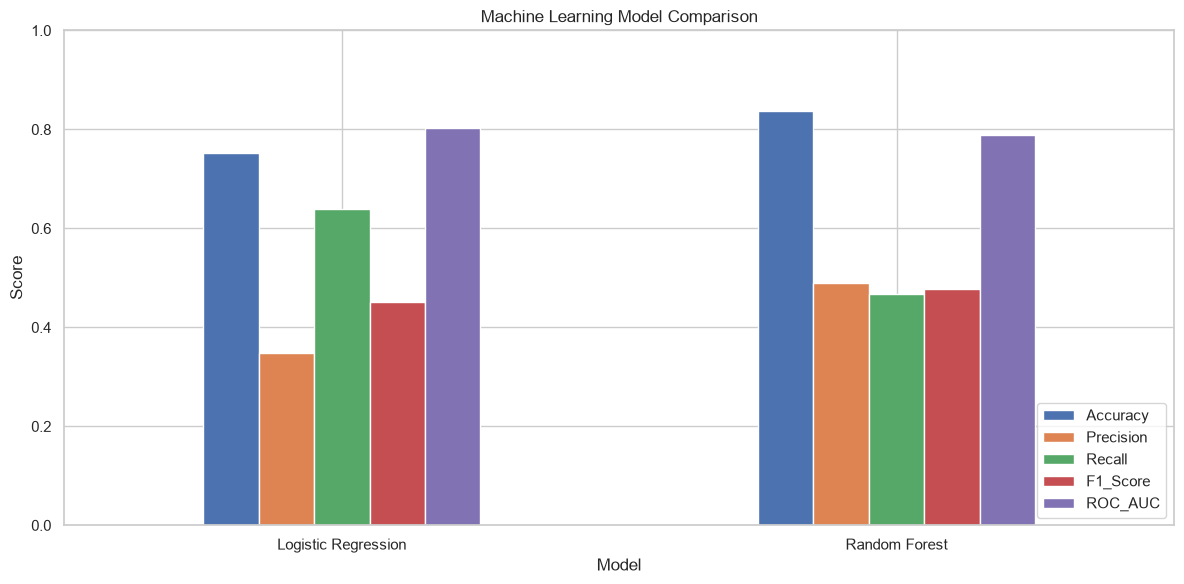

In [14]:
metrics = [
    "Accuracy",
    "Precision",
    "Recall",
    "F1_Score",
    "ROC_AUC"
]

comparison = results_df.set_index("Model")[metrics]

comparison.plot(
    kind="bar",
    figsize=(12, 6)
)

plt.title("Machine Learning Model Comparison")
plt.ylabel("Score")
plt.xlabel("Model")
plt.ylim(0, 1)
plt.xticks(rotation=0)
plt.legend(loc="lower right")
plt.tight_layout()

plt.savefig(
    PROJECT_ROOT / "images" / "model_comparison.png",
    dpi=300
)

plt.show()

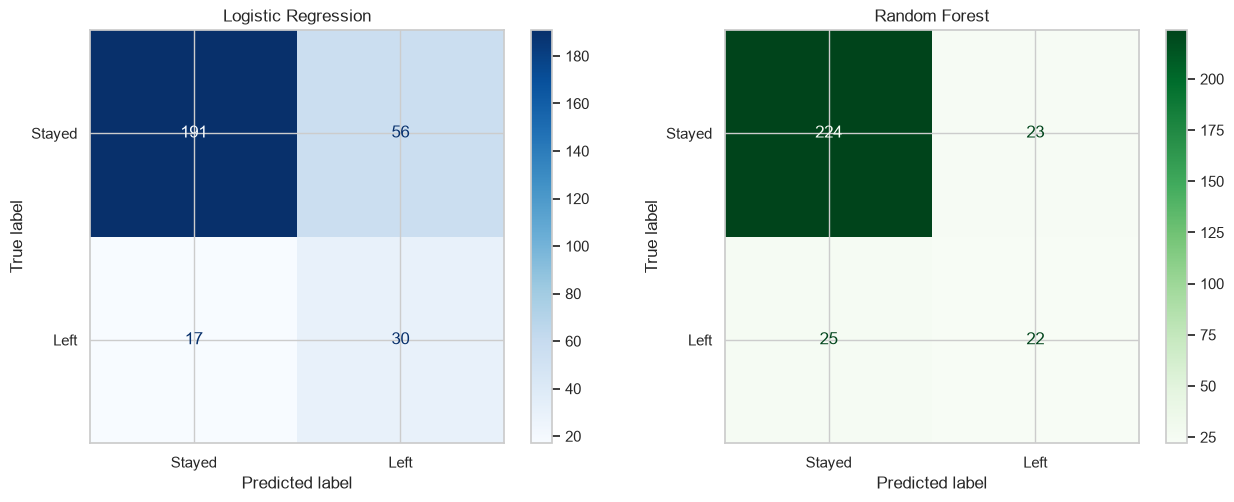

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

ConfusionMatrixDisplay.from_predictions(
    y_test,
    lr_predictions,
    display_labels=["Stayed", "Left"],
    cmap="Blues",
    ax=axes[0]
)

axes[0].set_title("Logistic Regression")

ConfusionMatrixDisplay.from_predictions(
    y_test,
    rf_predictions,
    display_labels=["Stayed", "Left"],
    cmap="Greens",
    ax=axes[1]
)

axes[1].set_title("Random Forest")

plt.tight_layout()

plt.savefig(
    PROJECT_ROOT / "images" / "confusion_matrices.png",
    dpi=300
)

plt.show()

In [16]:
print("LOGISTIC REGRESSION REPORT")
print(
    classification_report(
        y_test,
        lr_predictions,
        target_names=["Stayed", "Left"],
        zero_division=0
    )
)

print("\nRANDOM FOREST REPORT")
print(
    classification_report(
        y_test,
        rf_predictions,
        target_names=["Stayed", "Left"],
        zero_division=0
    )
)

LOGISTIC REGRESSION REPORT
              precision    recall  f1-score   support

      Stayed       0.92      0.77      0.84       247
        Left       0.35      0.64      0.45        47

    accuracy                           0.75       294
   macro avg       0.63      0.71      0.65       294
weighted avg       0.83      0.75      0.78       294


RANDOM FOREST REPORT
              precision    recall  f1-score   support

      Stayed       0.90      0.91      0.90       247
        Left       0.49      0.47      0.48        47

    accuracy                           0.84       294
   macro avg       0.69      0.69      0.69       294
weighted avg       0.83      0.84      0.84       294



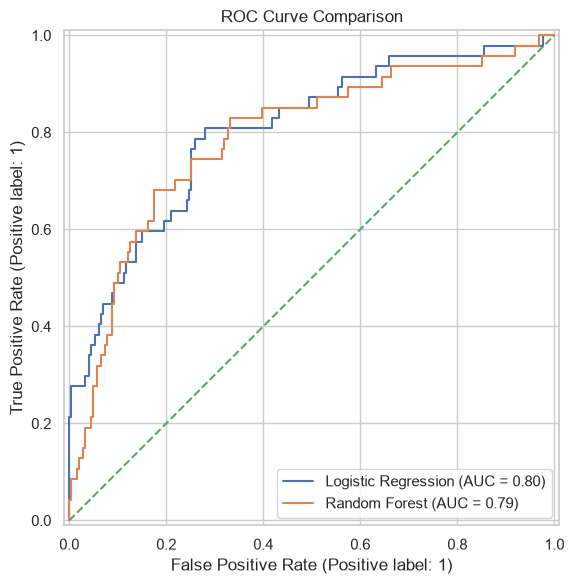

In [17]:
fig, ax = plt.subplots(figsize=(8, 6))

RocCurveDisplay.from_predictions(
    y_test,
    lr_probabilities,
    name="Logistic Regression",
    ax=ax
)

RocCurveDisplay.from_predictions(
    y_test,
    rf_probabilities,
    name="Random Forest",
    ax=ax
)

ax.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Random baseline"
)

plt.title("ROC Curve Comparison")
plt.tight_layout()

plt.savefig(
    PROJECT_ROOT / "images" / "roc_curve_comparison.png",
    dpi=300
)

plt.show()

In [18]:
best_model_name = results_df.loc[
    results_df["F1_Score"].idxmax(),
    "Model"
]

if best_model_name == "Logistic Regression":
    best_model = logistic_model
else:
    best_model = random_forest_model

print("Selected Model:", best_model_name)

Selected Model: Random Forest


In [19]:
MODEL_DIR = PROJECT_ROOT / "models"
REPORT_DIR = PROJECT_ROOT / "reports"

MODEL_DIR.mkdir(parents=True, exist_ok=True)
REPORT_DIR.mkdir(parents=True, exist_ok=True)

model_path = MODEL_DIR / "best_attrition_model.pkl"

joblib.dump(best_model, model_path)

print("Best model saved successfully!")
print("Model:", best_model_name)
print("Location:", model_path)

Best model saved successfully!
Model: Random Forest
Location: c:\Users\gupta\OneDrive\Desktop\Employee-Attrition-Prediction\models\best_attrition_model.pkl


In [20]:
results_df.to_csv(
    REPORT_DIR / "model_comparison.csv",
    index=False
)

print("Model comparison report saved!")

Model comparison report saved!


In [23]:
best_predictions = best_model.predict(X_test)
best_probabilities = best_model.predict_proba(X_test)[:, 1]

prediction_report = pd.DataFrame({
    "EmployeeID": df.loc[X_test.index, "EmployeeID"].values,
    "Actual_Attrition": y_test.map({
        0: "No",
        1: "Yes"
    }).values,
    "Predicted_Attrition": np.where(
        best_predictions == 1, "Yes", "No"
    ),
    "Attrition_Probability": best_probabilities
})

prediction_report.to_csv(
    REPORT_DIR / "employee_predictions.csv",
    index=False
)

display(prediction_report.head(10))

,EmployeeID,Actual_Attrition,Predicted_Attrition,Attrition_Probability
0,1495,No,Yes,0.738686
1,1246,No,No,0.169788
2,613,No,No,0.268953
3,1288,No,No,0.076221
4,90,Yes,Yes,0.500985
5,1641,No,No,0.298387
6,543,No,No,0.214098
7,1866,No,No,0.131327
8,1728,No,No,0.054102
9,1839,No,Yes,0.614452
